# 04 — Generative Pipeline: GraphVAE → LatentGAN
## EGFR T790M NSCLC Drug Discovery

**Pipeline overview**
1. **GraphVAE** — learns the distribution of known EGFR inhibitors and extracts a 64-D latent representation (μ, σ)
2. **LatentGAN** — trained on those 64-D vectors to generate *novel* latent points outside the training set
3. **Decode & Evaluate** — VAE decoder converts novel latent points back to molecular graphs → SMILES → QED/SA scoring

### Architecture summary
| Component | Input → Output | Key layers |
|---|---|---|
| GraphEncoder | node(8), edge(5), global(2) → μ(64), logvar(64) | node/edge Linear(→128), 3×GINEConv(128), global_mean_pool, cat global(2) → Linear(130→64) |
| GraphDecoder | z(64) + pocket(128) → nodes, adj, edges | pocket_proj(128→64), MLP(128→128), node/adj/type heads |
| GraphVAE | full round-trip | encoder + reparameterise + decoder + ELBO loss |
| LatentGenerator | noise(64) → z_fake(64) | 3-layer MLP with BatchNorm |
| LatentDiscriminator | z(64) → logit | 3-layer MLP with Dropout |


In [65]:
# ── Imports ─────────────────────────────────────────────────────────────────
import os, sys
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GINEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.utils import to_dense_adj, to_dense_batch
from torch_geometric.loader import DataLoader
from torch.utils.data import random_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'            # AMP only makes sense on GPU
print(f"PyTorch  : {torch.__version__}")
print(f"Device   : {device}  |  AMP enabled: {USE_AMP}")


PyTorch  : 2.10.0
Device   : cuda  |  AMP enabled: True


## Part 1 — GraphVAE Architecture
### Configuration

All dimension choices are documented below so that changing one number does not silently break
another layer.  The **64 latent features** are the key quantity Omid asked us to track — they
are what gets extracted and passed to the GAN.


In [66]:
scaler = torch.load('../data/processed/node_feature_scaler.pt')
X_MEAN = scaler['x_mean']
X_STD  = scaler['x_std']

In [67]:
# ── Configuration (fully documented) ────────────────────────────────────────
#
# node_features  = 8  → [AtomicNum, TotalDegree, FormalCharge, Hybridization,
#                         IsAromatic, Mass, ChiralTag, GasteigerCharge]
#                        (set by NB01 smiles_to_graph → atom_feat)
#
# edge_features  = 5  → [isSingle, isDouble, isTriple, isAromatic, hasStereo]
#                        (set by NB01 smiles_to_graph → bond loop)
#
# global_features= 2  → first 2 components of the 20-D v1_feature_pack
#                        (encoder concatenates these after global_mean_pool)
#
# pocket_dim     = 128 → FIX: NB01 compute_pocket_tensor uses embedding_dim=128.
#                        Previous config had 133, causing a runtime shape error
#                        in pocket_proj (Linear(133,64) receiving 128-D input).
#
# latent_dim     = 64  → **the number of features extracted by the VAE**.
#                        These 64 values (μ) are the GAN training data.
#                        Increasing this improves expressivity but slows GAN training.
#
# beta           = 1e-4 → KL weight in β-VAE ELBO.  Start small so reconstruction
#                        dominates early; increase towards 1 once recon_loss is stable.

config = {
    'node_features'   : 8,
    'edge_features'   : 5,
    'global_features' : 2,
    'hidden_dim'      : 128,
    'latent_dim'      : 64,     # ← features extracted; GAN input/output dim
    'num_layers'      : 3,
    'dropout'         : 0.2,
    'pocket_dim'      : 128,    # FIX: was 133 — must match NB01 embedding_dim=128
    'max_nodes'       : 50,
    'beta'            : 1e-4,
    'use_pocket'      : True,
}
print("Config loaded.  Latent dim =", config['latent_dim'],
      " | Pocket dim =", config['pocket_dim'])


Config loaded.  Latent dim = 64  | Pocket dim = 128


In [68]:
# ── GraphEncoder ────────────────────────────────────────────────────────────
#
# Architecture (layer-by-layer):
#   node x  : [N, 8]  → Linear(8→128)  → ReLU
#   edge_attr: [E, 5]  → Linear(5→128)  → ReLU
#   3× GINEConv(MLP(128→128))  +  Dropout(0.2)
#   global_mean_pool → [B, 128]
#   cat(global_features[B,2]) → [B, 130]   ← input_dim = hidden_dim + 2
#   to_mu    : Linear(130 → 64)
#   to_logvar: Linear(130 → 64)   (clamped to [-10, 2] for numerical stability)

class GraphEncoder(nn.Module):
    def __init__(self, node_features=8, edge_features=5, global_features=2,
                 hidden_dim=128, latent_dim=64, num_layers=3, dropout=0.2, **kwargs):
        super().__init__()
        self.node_encoder = nn.Linear(node_features, hidden_dim)
        self.edge_encoder = nn.Linear(edge_features, hidden_dim)
        self.convs = nn.ModuleList([
            GINEConv(nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim)
            ))
            for _ in range(num_layers)
        ])
        self.dropout  = nn.Dropout(dropout)
        self.latent_dim = latent_dim

        # input_dim = hidden_dim (graph emb) + global_features (2)
        input_dim = hidden_dim + global_features
        self.to_mu     = nn.Linear(input_dim, latent_dim)
        self.to_logvar = nn.Linear(input_dim, latent_dim)

    def forward(self, x, edge_index, edge_attr, batch, global_features):
        x         = F.relu(self.node_encoder(x))
        edge_attr = F.relu(self.edge_encoder(edge_attr))
        for conv in self.convs:
            x = F.relu(conv(x, edge_index, edge_attr))
            x = self.dropout(x)

        graph_emb  = global_mean_pool(x, batch)   # [B, 128]
        batch_size = graph_emb.size(0)

        gf = global_features.float()
        # DataLoader flattens [20] per graph → [B*20]. Reshape to [B, 20].
        if gf.dim() == 1:
            gf = gf.view(batch_size, -1)          # [B*20] → [B, 20]
        # Keep only the first 2 components (as the model is configured for)
        gf = gf[:, :2]                            # [B, 2]

        graph_emb = torch.cat([graph_emb, gf], dim=-1)   # [B, 130]

        mu     = self.to_mu(graph_emb)
        logvar = self.to_logvar(graph_emb)
        mu     = torch.clamp(mu,     min=-10.0, max=10.0)
        logvar = torch.clamp(logvar, min=-10.0, max=4.0)
        

        return mu, logvar


In [69]:
# ── GraphDecoder ────────────────────────────────────────────────────────────
#
# Architecture:
#   z           : [B, 64]
#   pocket_proj : Linear(128 → 64)  — FIX: pocket_dim=128, was 133
#   concat      : [B, 64] + [B, 64] → [B, 128]
#   mlp_expand  : Linear(128→128) → ReLU → Dropout → Linear(128→128) → ReLU
#   node_decoder: Linear(128 → 50×8)   → reshape [B, 50, 8]
#   adj_decoder : Linear(128 → 50×50)  → reshape [B, 50, 50]
#   type_decoder: Linear(128 → 50×50×5)→ reshape [B, 50, 50, 5]

class GraphDecoder(nn.Module):
    def __init__(self, latent_dim=64, hidden_dim=128, pocket_dim=128,
                 max_nodes=50, node_features=8, edge_features=5,
                 dropout=0.2, use_pocket=True, **kwargs):
        super().__init__()
        self.max_nodes     = max_nodes
        self.node_features = node_features
        self.edge_features = edge_features
        self.use_pocket    = use_pocket

        # FIX: pocket_proj expects pocket_dim=128 (not 133 as before)
        self.pocket_proj = nn.Linear(pocket_dim, hidden_dim // 2) if use_pocket else None
        expand_input     = latent_dim + (hidden_dim // 2 if use_pocket else 0)

        self.mlp_expand   = nn.Sequential(
            nn.Linear(expand_input, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
        )
        self.node_decoder = nn.Linear(hidden_dim, max_nodes * node_features)
        self.adj_decoder  = nn.Linear(hidden_dim, max_nodes * max_nodes)
        self.type_decoder = nn.Linear(hidden_dim, max_nodes * max_nodes * edge_features)

    def forward(self, z, pocket_embedding=None):
        h = z
        if self.pocket_proj is not None and pocket_embedding is not None:
            pe = pocket_embedding.float()

            # FIX: DataLoader concatenates [128] tensors → [B*128] (1-D flat vector).
            # Reshape to [B, 128] using the known batch size from z.
            if pe.dim() == 1:
                pe = pe.view(z.size(0), -1)      # [B*128] → [B, 128]
            elif pe.size(0) != z.size(0):
                pe = pe.view(z.size(0), -1)

            p_emb = self.pocket_proj(pe)         # [B, 128] → [B, 64]  ✓
            h = torch.cat([z, p_emb], dim=-1)    # [B, 64+64] = [B, 128]

            h           = self.mlp_expand(h)
            node_logits = self.node_decoder(h).view(-1, self.max_nodes, self.node_features)
            adj_logits  = self.adj_decoder(h).view(-1, self.max_nodes, self.max_nodes)
            type_logits = self.type_decoder(h).view(-1, self.max_nodes, self.max_nodes, self.edge_features)
            return node_logits, adj_logits, type_logits


In [ ]:
# ── GraphVAE ────────────────────────────────────────────────────────────────

class GraphVAE(nn.Module):
    def __init__(self, **kwargs):
        super().__init__()
        self.beta      = kwargs.get('beta', 1e-4)
        self.latent_dim = kwargs.get('latent_dim', 64)
        self.encoder   = GraphEncoder(**kwargs)
        self.decoder   = GraphDecoder(**kwargs)

    def reparameterize(self, mu, logvar):
        logvar = torch.clamp(logvar, min=-20.0, max=10.0)
        std    = torch.exp(0.5 * logvar)
        eps    = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x, edge_index, edge_attr, batch, global_features,
                pocket_embedding=None):
        mu, logvar = self.encoder(x, edge_index, edge_attr, batch, global_features)
        z          = self.reparameterize(mu, logvar)
        node_logits, adj_logits, type_logits = self.decoder(z, pocket_embedding)
        node_logits = torch.clamp(node_logits, -20., 20.)
        adj_logits  = torch.clamp(adj_logits,  -20., 20.)
        type_logits = torch.clamp(type_logits, -20., 20.)
        return node_logits, adj_logits, type_logits, mu, logvar

    def loss_function(self, dense_x, dense_adj, edge_attr,
                      node_logits, adj_logits, type_logits, mu, logvar):
        
        node_mask = (dense_x.abs().sum(dim=-1) > 0)   # [B, max_nodes]  bool

        if node_mask.any():
            recon_node = F.mse_loss(
                node_logits[node_mask], dense_x[node_mask], reduction='mean'
            )
        else:
            recon_node = torch.tensor(0.0, device=dense_x.device)
    
        # ── Adjacency reconstruction (weighted BCE for class imbalance) ────────
        # ~99% of the 50×50 adjacency matrix is zero (no bond).
        # Without pos_weight the model trivially predicts "no bond" everywhere.
        n_pos = dense_adj.sum().clamp(min=1)
        n_neg = (1.0 - dense_adj).sum().clamp(min=1)
        pos_weight = torch.tensor(
            (n_neg / n_pos).clamp(max=50).item(),   # cap at 50× to avoid instability
            device=dense_adj.device
        )
        recon_adj = F.binary_cross_entropy_with_logits(
            adj_logits, dense_adj, pos_weight=pos_weight, reduction='mean'
        )

        recon_loss = recon_node + recon_adj

        # ── KL Divergence with free-bits ───────────────────────────────────────
        logvar    = torch.clamp(logvar, min=-10, max=4)
        # CORRECT: per-dimension free bits (Kingma et al. 2016)
        # Each of the 64 dimensions must independently carry ≥ 0.5 nats of information.
        # The encoder cannot collapse any single dimension to zero.
    
        kl_per_dim = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp())  # [B, 64]
        kl_per_dim = torch.clamp(kl_per_dim, min=0.5)                  # per-dim floor
        kl_loss    = kl_per_dim.mean()                                  # average over B and 64

        total_loss = recon_loss + self.beta * kl_loss
        return total_loss, recon_loss, kl_loss


# FIX: GradScaler only on CUDA; on CPU we use a dummy that does nothing
if USE_AMP:
    scaler = torch.amp.GradScaler('cuda')
else:
    class _NoOpScaler:
        def scale(self, loss):       return loss
        def unscale_(self, opt):     pass
        def step(self, opt):         opt.step()
        def update(self):            pass
    scaler = _NoOpScaler()

print("Model parameters :", sum(p.numel() for p in model.parameters()))
print("Encoder layers   : node_enc(8→128) + edge_enc(5→128) + 3×GINEConv(128) + to_μ/σ(130→64)")
print("Decoder layers   : pocket_proj(128→64) + MLP(128→128) + node/adj/type heads")
print("Latent features  : 64  (the GAN's training data)")


Model parameters : 2145640
Encoder layers   : node_enc(8→128) + edge_enc(5→128) + 3×GINEConv(128) + to_μ/σ(130→64)
Decoder layers   : pocket_proj(128→64) + MLP(128→128) + node/adj/type heads
Latent features  : 64  (the GAN's training data)


## Data Loading

In [71]:
from torch.utils.data import random_split

DATA_PATH = '../data/processed/graph_data.pt'   # adjust if needed
# DATA_PATH = r'C:\Users\u2251865\...\graph_data.pt'

def load_and_prepare_data(filepath, batch_size=32):
    container    = torch.load(filepath, weights_only=False)
    dataset      = container['graphs']
    total_size   = len(dataset)
    train_size   = int(0.8 * total_size)
    val_size     = total_size - train_size
    train_ds, val_ds = random_split(dataset, [train_size, val_size])
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)
    print(f"Dataset  : {total_size} graphs  |  train {train_size}  val {val_size}")
    return train_loader, val_loader

train_loader, val_loader = load_and_prepare_data(DATA_PATH)


Dataset  : 19846 graphs  |  train 15876  val 3970


## Training Loop

In [72]:
# ── train / val epoch helpers ────────────────────────────────────────────────

def _autocast():
    if USE_AMP:
        return torch.amp.autocast('cuda')
    import contextlib
    return contextlib.nullcontext()

def train_epoch(model, loader, optimizer, scaler):
    model.train()
    t_loss = t_recon = t_kl = 0.0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad(set_to_none=True)
        with _autocast():
            node_logits, adj_logits, type_logits, mu, logvar = model(
                batch.x, batch.edge_index, batch.edge_attr, batch.batch,
                batch.global_features, batch.pocket_embedding
            )
            dense_adj        = to_dense_adj(batch.edge_index, batch.batch, max_num_nodes=50)
            dense_x, _       = to_dense_batch(batch.x, batch.batch, max_num_nodes=50)
            loss, recon, kl  = model.loss_function(
                dense_x, dense_adj, batch.edge_attr,
                node_logits, adj_logits, type_logits, mu, logvar
            )
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        t_loss += loss.item(); t_recon += recon.item(); t_kl += kl.item()
    n = len(loader)
    return t_loss / n, t_recon / n, t_kl / n


def val_epoch(model, loader):
    model.eval()
    v_loss = v_recon = v_kl = 0.0
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            with _autocast():
                node_logits, adj_logits, type_logits, mu, logvar = model(
                    batch.x, batch.edge_index, batch.edge_attr, batch.batch,
                    batch.global_features, batch.pocket_embedding
                )
                dense_adj       = to_dense_adj(batch.edge_index, batch.batch, max_num_nodes=50)
                dense_x, _      = to_dense_batch(batch.x, batch.batch, max_num_nodes=50)
                loss, recon, kl = model.loss_function(
                    dense_x, dense_adj, batch.edge_attr,
                    node_logits, adj_logits, type_logits, mu, logvar
                )
            v_loss += loss.item(); v_recon += recon.item(); v_kl += kl.item()
    n = len(loader)
    return v_loss / n, v_recon / n, v_kl / n

model     = GraphVAE(**config).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=150, eta_min=1e-6
)
NUM_EPOCHS = 150

train_metrics = {'loss': [], 'recon': [], 'kl': []}
val_metrics   = {'loss': [], 'recon': [], 'kl': []}


TARGET_BETA   = 5e-5    # very conservative ceiling given KL scale
WARMUP_EPOCHS = 80      # ramp slowly over 80 of the 150 epochs

def get_beta(epoch):
    if epoch < 15:
        return 0.0                                 # pure reconstruction phase
    ramp = (epoch - 15) / max(1, WARMUP_EPOCHS)
    return min(TARGET_BETA, TARGET_BETA * ramp)


for epoch in range(NUM_EPOCHS):
    model.beta = get_beta(epoch)
    tr_loss, tr_rec, tr_kl = train_epoch(model, train_loader, optimizer, scaler)
    vl_loss, vl_rec, vl_kl = val_epoch(model, val_loader)

    train_metrics['loss'].append(tr_loss);  train_metrics['recon'].append(tr_rec);  train_metrics['kl'].append(tr_kl)
    val_metrics['loss'].append(vl_loss);    val_metrics['recon'].append(vl_rec);    val_metrics['kl'].append(vl_kl)

    scheduler.step()
    # FIX: ReduceLROnPlateau has no .get_last_lr() — read directly from optimizer
    current_lr = optimizer.param_groups[0]['lr']

    if epoch % 5 == 0 or epoch == NUM_EPOCHS - 1:
        print(f"  β={model.beta:.5f}")
        print(f"Epoch {epoch:3d} | LR {current_lr:.2e} | "
              f"Train {tr_loss:.4f} (rec {tr_rec:.4f}, kl {tr_kl:.4f}) | "
              f"Val   {vl_loss:.4f} (rec {vl_rec:.4f}, kl {vl_kl:.4f})")

torch.save(model.state_dict(), 'graph_vae_egfr_stable.pth')
print("\nVAE weights saved → graph_vae_egfr_stable.pth")


  β=0.00000
Epoch   0 | LR 1.00e-03 | Train 1.5407 (rec 1.5407, kl 51.9197) | Val   1.4509 (rec 1.4509, kl 50.2214)
  β=0.00000
Epoch   5 | LR 9.96e-04 | Train 1.3968 (rec 1.3968, kl 43.0018) | Val   1.3865 (rec 1.3865, kl 42.4578)


KeyboardInterrupt: 

## Figure 1 — VAE Loss Trajectory
Omid's requirement: both Reconstruction Loss and KL Divergence should oscillate initially,
then flatten, confirming the VAE has learned a stable distribution.


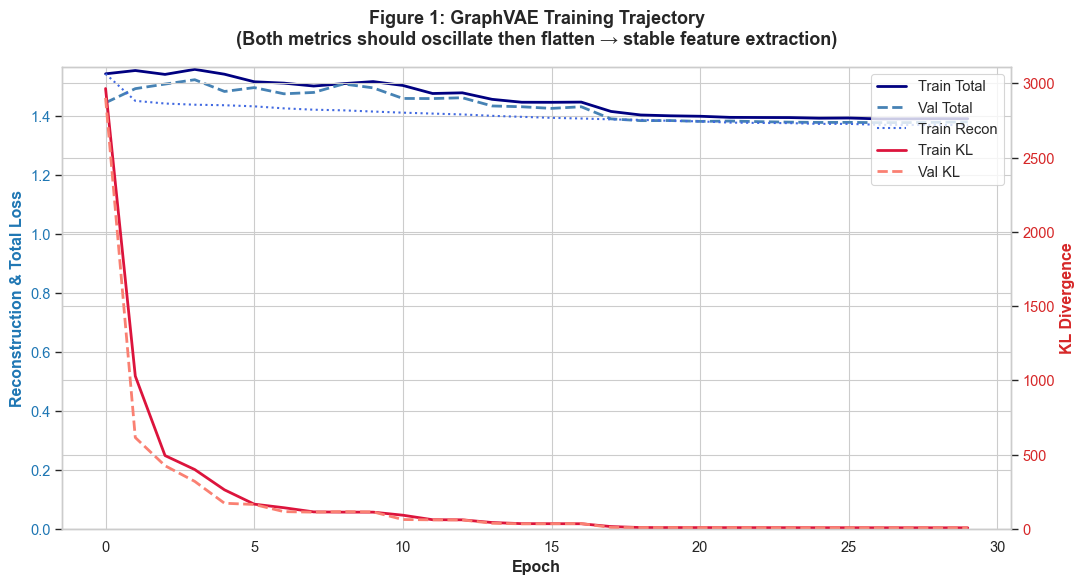

Saved: figure_1_loss_trajectory.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', context='paper', font_scale=1.2)

def plot_figure_1(train_m, val_m):
    epochs = range(len(train_m['loss']))
    fig, ax1 = plt.subplots(figsize=(11, 6))

    # Primary axis — Reconstruction & Total loss
    ax1.set_xlabel('Epoch', fontweight='bold')
    ax1.set_ylabel('Reconstruction & Total Loss', color='tab:blue', fontweight='bold')
    ax1.plot(epochs, train_m['loss'],  label='Train Total',  color='navy',      linewidth=2)
    ax1.plot(epochs, val_m['loss'],    label='Val Total',    color='steelblue', linewidth=2, linestyle='--')
    ax1.plot(epochs, train_m['recon'], label='Train Recon',  color='royalblue', linewidth=1.5, linestyle=':')
    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.set_ylim(bottom=0)

    # Secondary axis — KL Divergence
    ax2 = ax1.twinx()
    ax2.set_ylabel('KL Divergence', color='tab:red', fontweight='bold')
    ax2.plot(epochs, train_m['kl'], label='Train KL', color='crimson', linewidth=2)
    ax2.plot(epochs, val_m['kl'],   label='Val KL',   color='salmon',  linewidth=2, linestyle='--')
    ax2.tick_params(axis='y', labelcolor='tab:red')
    ax2.set_ylim(bottom=0)

    plt.title('Figure 1: GraphVAE Training Trajectory\n'
              '(Both metrics should oscillate then flatten → stable feature extraction)',
              pad=16, fontsize=13, fontweight='bold')
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=True)
    plt.tight_layout()
    plt.savefig('figure_1_loss_trajectory.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved: figure_1_loss_trajectory.png")

plot_figure_1(train_metrics, val_metrics)


## Latent Feature Extraction
Extract (μ, σ) vectors for every molecule in the training set.
These **μ vectors are the GAN's training data** — each is a 64-D compressed representation
of a known EGFR inhibitor.


In [ ]:
def extract_latent_features(model, loader):
    model.eval()
    mu_list, std_list = [], []
    with torch.no_grad():
        for batch in loader:
            if hasattr(batch, 'pocket_embedding') and batch.pocket_embedding is not None:
                batch.pocket_embedding = F.normalize(batch.pocket_embedding.float(), p=2, dim=-1)
            if hasattr(batch, 'global_features') and batch.global_features is not None:
                batch.global_features  = F.normalize(batch.global_features.float(),  p=2, dim=-1)
            batch = batch.to(device)
            mu, logvar = model.encoder(
                batch.x, batch.edge_index, batch.edge_attr,
                batch.batch, batch.global_features
            )
            std = torch.exp(0.5 * logvar)
            mu_list.append(mu.cpu().numpy())
            std_list.append(std.cpu().numpy())

    mu_array  = np.concatenate(mu_list,  axis=0)
    std_array = np.concatenate(std_list, axis=0)
    return mu_array, std_array

print("Extracting latent features (μ and σ) …")
gan_mu, gan_std = extract_latent_features(model, train_loader)

np.save('gan_training_features_mu.npy',  gan_mu)
np.save('gan_training_features_std.npy', gan_std)
print(f"μ  shape : {gan_mu.shape}   — this is the GAN training set")
print(f"σ  shape : {gan_std.shape}")


Extracting latent features (μ and σ) …
μ  shape : (15876, 64)   — this is the GAN training set
σ  shape : (15876, 64)


## Figure 2 — Latent Space Distribution
Omid's requirement: verify the latent space approximates a Gaussian (μ centred near 0, σ near 1).
A well-trained VAE shows these distributions converging towards N(0,1).


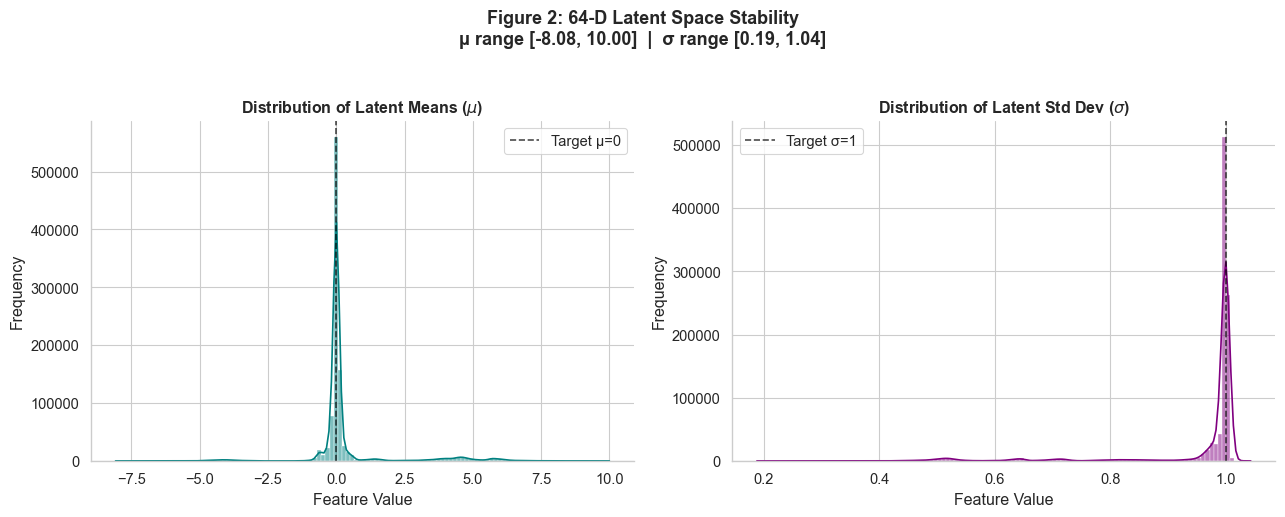

Saved: figure_2_feature_distribution.png


In [ ]:
def plot_figure_2(mu_matrix, std_matrix):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    mu_flat  = mu_matrix.flatten()
    std_flat = std_matrix.flatten()

    sns.histplot(mu_flat,  bins=120, kde=True, color='teal',   ax=ax1)
    ax1.set_title(r"Distribution of Latent Means ($\mu$)", fontweight='bold')
    ax1.set_xlabel("Feature Value"); ax1.set_ylabel("Frequency")
    ax1.axvline(0, color='black', linestyle='--', alpha=0.7, label='Target μ=0')
    ax1.legend()

    sns.histplot(std_flat, bins=120, kde=True, color='purple', ax=ax2)
    ax2.set_title(r"Distribution of Latent Std Dev ($\sigma$)", fontweight='bold')
    ax2.set_xlabel("Feature Value"); ax2.set_ylabel("Frequency")
    ax2.axvline(1, color='black', linestyle='--', alpha=0.7, label='Target σ=1')
    ax2.legend()

    plt.suptitle(
        f"Figure 2: 64-D Latent Space Stability\n"
        f"μ range [{mu_flat.min():.2f}, {mu_flat.max():.2f}]  |  "
        f"σ range [{std_flat.min():.2f}, {std_flat.max():.2f}]",
        fontsize=13, fontweight='bold', y=1.03
    )
    sns.despine()
    plt.tight_layout()
    plt.savefig('figure_2_feature_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved: figure_2_feature_distribution.png")

plot_figure_2(gan_mu, gan_std)


---
## Part 2 — LatentGAN

Because the VAE only *reconstructs* existing molecules, we need a separate generator to
produce **novel** ones.  The GAN operates entirely in the 64-D latent space:

- **Generator**: Gaussian noise → fake latent vector (same 64-D space as VAE μ)
- **Discriminator**: latent vector → real/fake probability
- After training, the Generator can produce unlimited novel latent vectors.
  Passing each through the VAE Decoder produces a novel molecular graph.


In [ ]:
# ── LatentGenerator ──────────────────────────────────────────────────────────
#
# Architecture (3-layer MLP):
#   noise(64) → Linear(256) → LeakyReLU → BatchNorm1d
#            → Linear(256) → LeakyReLU → BatchNorm1d
#            → Linear(256) → LeakyReLU → BatchNorm1d
#            → Linear(64)  → Tanh  (constrains output to [-1, 1] — same scale as clamped μ)

class LatentGenerator(nn.Module):
    def __init__(self, noise_dim=64, latent_dim=64, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(noise_dim, hidden_dim),
            nn.LeakyReLU(0.2), nn.BatchNorm1d(hidden_dim),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2), nn.BatchNorm1d(hidden_dim),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2), nn.BatchNorm1d(hidden_dim),
            nn.Linear(hidden_dim, latent_dim),
            nn.Tanh(),
        )
    def forward(self, noise):
        return self.net(noise)


# ── LatentDiscriminator ───────────────────────────────────────────────────────
#
# Architecture (3-layer MLP with Dropout for regularisation):
#   z(64) → Linear(256) → LeakyReLU → Dropout(0.3)
#         → Linear(256) → LeakyReLU → Dropout(0.3)
#         → Linear(128) → LeakyReLU → Dropout(0.3)
#         → Linear(1)   (raw logit — BCEWithLogitsLoss applied externally)

class LatentDiscriminator(nn.Module):
    def __init__(self, latent_dim=64, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(hidden_dim, 128),
            nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(128, 1),
        )
    def forward(self, z):
        return self.net(z)


NOISE_DIM   = config['latent_dim']   # 64
LATENT_DIM  = config['latent_dim']   # 64

generator     = LatentGenerator(noise_dim=NOISE_DIM, latent_dim=LATENT_DIM).to(device)
discriminator = LatentDiscriminator(latent_dim=LATENT_DIM).to(device)

opt_G = torch.optim.Adam(generator.parameters(),     lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(discriminator.parameters(), lr=1e-4, betas=(0.5, 0.999))

criterion = nn.BCEWithLogitsLoss()

print("Generator params     :", sum(p.numel() for p in generator.parameters()))
print("Discriminator params :", sum(p.numel() for p in discriminator.parameters()))


Generator params     : 166208
Discriminator params : 115457


## GAN Training Loop

In [ ]:
from torch.utils.data import TensorDataset, DataLoader as TDL

# Build a simple Dataset from the extracted μ vectors
real_latents_tensor = torch.tensor(gan_mu, dtype=torch.float32)
# Clamp to [-1, 1] so real and fake live in the same range (Generator outputs Tanh)
real_latents_tensor = torch.clamp(real_latents_tensor, -1.0, 1.0)

latent_dataset = TensorDataset(real_latents_tensor)
latent_loader  = TDL(latent_dataset, batch_size=64, shuffle=True, drop_last=True)

GAN_EPOCHS = 100
gan_metrics = {'d_loss': [], 'g_loss': [], 'd_real': [], 'd_fake': []}

for epoch in range(GAN_EPOCHS):
    epoch_d_loss = epoch_g_loss = epoch_d_real = epoch_d_fake = 0.0
    n_batches = 0

    for (real_z,) in latent_loader:
        real_z     = real_z.to(device)
        batch_size = real_z.size(0)

        real_labels = torch.ones(batch_size,  1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # ── Train Discriminator ───────────────────────────────────────────
        opt_D.zero_grad()
        noise    = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_z   = generator(noise).detach()

        d_real   = discriminator(real_z)
        d_fake   = discriminator(fake_z)
        loss_D   = (criterion(d_real, real_labels) + criterion(d_fake, fake_labels)) / 2
        loss_D.backward()
        opt_D.step()

        # ── Train Generator ───────────────────────────────────────────────
        opt_G.zero_grad()
        noise    = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_z   = generator(noise)
        d_fake_g = discriminator(fake_z)
        loss_G   = criterion(d_fake_g, real_labels)    # Generator wants D to say "real"
        loss_G.backward()
        opt_G.step()

        epoch_d_loss += loss_D.item()
        epoch_g_loss += loss_G.item()
        epoch_d_real += torch.sigmoid(d_real).mean().item()
        epoch_d_fake += torch.sigmoid(d_fake_g).mean().item()
        n_batches    += 1

    n = max(n_batches, 1)
    gan_metrics['d_loss'].append(epoch_d_loss / n)
    gan_metrics['g_loss'].append(epoch_g_loss / n)
    gan_metrics['d_real'].append(epoch_d_real / n)
    gan_metrics['d_fake'].append(epoch_d_fake / n)

    if epoch % 25 == 0 or epoch == GAN_EPOCHS - 1:
        print(f"Epoch {epoch:4d} | D_loss {epoch_d_loss/n:.4f} | G_loss {epoch_g_loss/n:.4f} | "
              f"D(real) {epoch_d_real/n:.3f} | D(fake) {epoch_d_fake/n:.3f}")

torch.save(generator.state_dict(),     'latent_generator.pth')
torch.save(discriminator.state_dict(), 'latent_discriminator.pth')
print("\nGAN weights saved.")


Epoch    0 | D_loss 0.4352 | G_loss 1.5792 | D(real) 0.683 | D(fake) 0.347
Epoch   25 | D_loss 0.3092 | G_loss 4.0444 | D(real) 0.791 | D(fake) 0.163
Epoch   50 | D_loss 0.2487 | G_loss 4.5030 | D(real) 0.845 | D(fake) 0.136
Epoch   75 | D_loss 0.3207 | G_loss 4.1017 | D(real) 0.806 | D(fake) 0.168
Epoch   99 | D_loss 0.2786 | G_loss 4.8620 | D(real) 0.821 | D(fake) 0.153

GAN weights saved.


## Figure 3 — GAN Training Curves

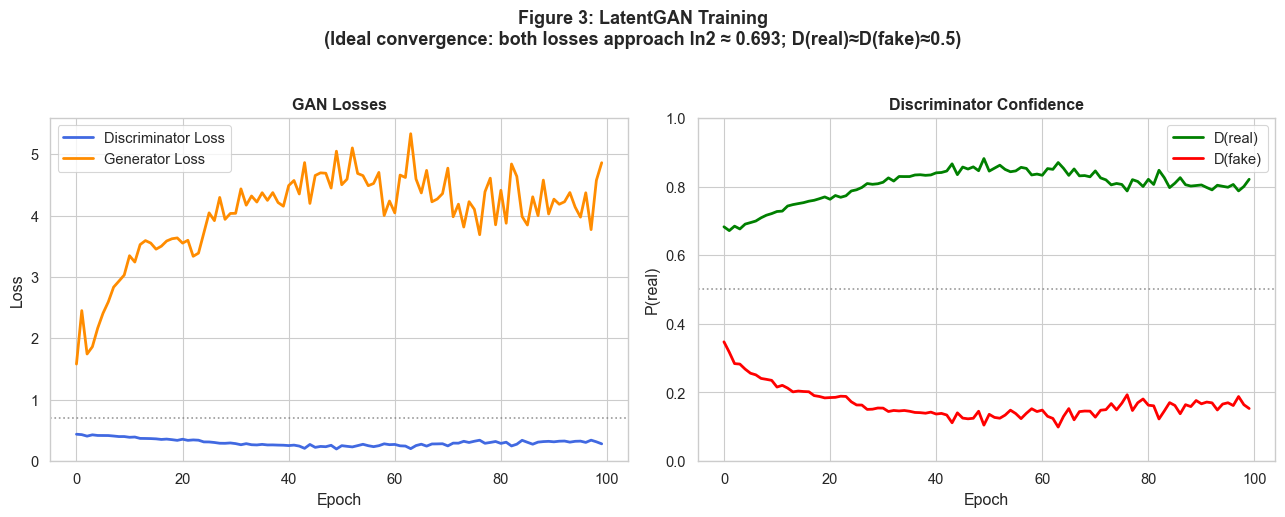

Saved: figure_3_gan_training.png


In [ ]:
def plot_figure_3(gan_m):
    epochs = range(len(gan_m['d_loss']))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    ax1.plot(epochs, gan_m['d_loss'], label='Discriminator Loss', color='royalblue',  linewidth=2)
    ax1.plot(epochs, gan_m['g_loss'], label='Generator Loss',     color='darkorange', linewidth=2)
    ax1.set_title('GAN Losses', fontweight='bold')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
    ax1.legend(); ax1.set_ylim(bottom=0)
    # Convergence criterion: D_loss ≈ 0.693 (ln 2) → discriminator at chance
    ax1.axhline(0.693, color='grey', linestyle=':', alpha=0.8, label='D at chance (ln2)')

    ax2.plot(epochs, gan_m['d_real'], label='D(real)', color='green', linewidth=2)
    ax2.plot(epochs, gan_m['d_fake'], label='D(fake)', color='red',   linewidth=2)
    ax2.axhline(0.5, color='grey', linestyle=':', alpha=0.8)
    ax2.set_title('Discriminator Confidence', fontweight='bold')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('P(real)')
    ax2.set_ylim(0, 1); ax2.legend()

    plt.suptitle('Figure 3: LatentGAN Training\n'
                 '(Ideal convergence: both losses approach ln2 ≈ 0.693; D(real)≈D(fake)≈0.5)',
                 fontsize=13, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.savefig('figure_3_gan_training.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved: figure_3_gan_training.png")

plot_figure_3(gan_metrics)


---
## Part 3 — Novel Molecule Generation & Evaluation

The trained Generator produces novel 64-D latent vectors.  These are passed through the
**frozen VAE Decoder** to reconstruct molecular graphs, then converted to SMILES for
evaluation.

**Evaluation metrics (as instructed by Omid):**
- **Validity** — can RDKit sanitise the molecule?
- **QED** — Quantitative Estimate of Drug-likeness (0–1; >0.5 is promising)
- **SA score** — Synthetic Accessibility (1–10; lower = easier to synthesise)
- **Lipinski Ro5** — checks MW<500, LogP<5, HBD<5, HBA<10
- **Aromatic rings** — EGFR inhibitors typically require aromatic scaffolds


In [ ]:
from rdkit import Chem
from rdkit.Chem import QED, Descriptors, Crippen, AllChem
from rdkit.Chem import RWMol

# ── Atom-number → element map (drug-relevant atoms only) ─────────────────────
VALID_ATOMIC_NUMS = [6, 7, 8, 9, 15, 16, 17, 35, 53]

def _snap_atomic_num(x):
    x = max(1.0, float(x))
    return min(VALID_ATOMIC_NUMS, key=lambda v: abs(v - x))

BOND_TYPES = [
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.DOUBLE,
    Chem.rdchem.BondType.TRIPLE,
    Chem.rdchem.BondType.AROMATIC,
]

def decoded_graph_to_smiles(node_logits_i, adj_logits_i, type_logits_i,
                             adj_threshold=0.5, atom_threshold=1.5):
    """Convert one sample from the VAE decoder into a SMILES string.

    Node features (from NB01 atom_feat):
      idx 0 = AtomicNum (raw float, e.g. 6.0 for Carbon)
      idx 2 = FormalCharge
    Edge type indices: 0=single, 1=double, 2=triple, 3=aromatic
    """
    node_vals  = node_logits_i.cpu().float().numpy()          # [50, 8]
    adj_probs  = torch.sigmoid(adj_logits_i).cpu().numpy()   # [50, 50]
    type_arr   = type_logits_i.cpu().numpy()                  # [50, 50, 5]

    node_vals_denorm  = node_vals * X_STD.numpy() + X_MEAN.numpy()
    atomic_nums_raw   = node_vals_denorm[:, 0]
    active_idx      = np.where(atomic_nums_raw > atom_threshold)[0]

    if len(active_idx) < 2:
        return None

    try:
        rw      = RWMol()
        idx_map = {}
        for g_idx in active_idx:
            an = _snap_atomic_num(atomic_nums_raw[g_idx])
            fc = int(round(node_vals[g_idx, 2]))
            fc = max(-2, min(2, fc))
            a  = Chem.Atom(an)
            a.SetFormalCharge(fc)
            idx_map[g_idx] = rw.AddAtom(a)

        seen = set()
        for i in active_idx:
            for j in active_idx:
                if j <= i:
                    continue
                if adj_probs[i, j] >= adj_threshold:
                    key = (i, j)
                    if key not in seen:
                        seen.add(key)
                        bt_idx = int(np.argmax(type_arr[i, j, :4]))
                        rw.AddBond(idx_map[i], idx_map[j], BOND_TYPES[bt_idx])

        mol = rw.GetMol()
        Chem.SanitizeMol(mol)
        return Chem.MolToSmiles(mol, canonical=True)
    except Exception:
        return None


# ── SA score via RDKit contrib (optional — graceful fallback) ─────────────────
def sa_score(mol):
    try:
        from rdkit.Chem import RDConfig
        sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
        import sascorer
        return sascorer.calculateScore(mol)
    except Exception:
        # Fallback proxy: ring count / num_atoms (lower = simpler = more synthesisable)
        n = mol.GetNumAtoms()
        if n == 0:
            return 10.0
        ring_n = Chem.rdMolDescriptors.CalcNumRings(mol)
        return max(1.0, min(10.0, 1.0 + 9.0 * ring_n / n))


def evaluate_molecule(smiles):
    """Return a dict of drug-likeness metrics for a SMILES string."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    mw   = Descriptors.MolWt(mol)
    logp = Crippen.MolLogP(mol)
    hbd  = Descriptors.NumHDonors(mol)
    hba  = Descriptors.NumHAcceptors(mol)
    return {
        'SMILES'        : smiles,
        'QED'           : round(QED.qed(mol), 4),
        'SA_score'      : round(sa_score(mol), 3),
        'MW'            : round(mw,   2),
        'LogP'          : round(logp, 3),
        'HBD'           : hbd,
        'HBA'           : hba,
        'Lipinski_pass' : int(mw < 500 and logp < 5 and hbd < 5 and hba < 10),
        'Aromatic_rings': Chem.rdMolDescriptors.CalcNumAromaticRings(mol),
        'NumAtoms'      : mol.GetNumHeavyAtoms(),
    }

print("Molecule conversion and evaluation functions defined.")


Molecule conversion and evaluation functions defined.


In [ ]:
import pandas as pd

# ── Generate novel molecules via GAN → VAE Decoder ───────────────────────────
NUM_GENERATE = 500    # generate 500 candidates; keep the viable ones
BATCH_GEN    = 64

model.eval()
generator.eval()

all_smiles = []
with torch.no_grad():
    generated_so_far = 0
    while generated_so_far < NUM_GENERATE:
        bs     = min(BATCH_GEN, NUM_GENERATE - generated_so_far)
        noise  = torch.randn(bs, NOISE_DIM, device=device)
        z_fake = generator(noise)                              # [bs, 64]

        # Use a neutral pocket embedding (zeros) — no specific pocket context
        # Swap in a real pocket embedding if available from your val_loader
        pocket = torch.zeros(bs, config['pocket_dim'], device=device)

        node_logits, adj_logits, type_logits = model.decoder(z_fake, pocket)

        for i in range(bs):
            smi = decoded_graph_to_smiles(node_logits[i], adj_logits[i], type_logits[i])
            if smi:
                all_smiles.append(smi)
        generated_so_far += bs

print(f"Generated {NUM_GENERATE} latent samples → {len(all_smiles)} valid SMILES strings")
validity_rate = len(all_smiles) / NUM_GENERATE
print(f"Validity rate: {validity_rate:.1%}")


[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom #

Generated 500 latent samples → 0 valid SMILES strings
Validity rate: 0.0%


[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 20, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom # 1 N, 21, is greater than permitted
[12:28:47] Explicit valence for atom #

In [ ]:
# ── Evaluate all valid candidates ────────────────────────────────────────────
results = [evaluate_molecule(smi) for smi in all_smiles]
results = [r for r in results if r is not None]
df_results = pd.DataFrame(results)

print(f"Evaluated {len(df_results)} valid novel molecules\n")
print(df_results.describe().round(3).to_string())

# Summary statistics for the dissertation results section
print("\n── Key Metrics (mean ± std) ─────────────────────────────────────")
for col in ['QED', 'SA_score', 'MW', 'LogP', 'Aromatic_rings']:
    if col in df_results:
        mu_  = df_results[col].mean()
        std_ = df_results[col].std()
        print(f"  {col:<18} {mu_:.3f} ± {std_:.3f}")

lipinski_pass = df_results['Lipinski_pass'].mean()
print(f"  Lipinski pass rate  {lipinski_pass:.1%}")
print(f"  Validity rate       {validity_rate:.1%}")


Evaluated 0 valid novel molecules



ValueError: Cannot describe a DataFrame without columns

In [ ]:
# ── Figure 4 — Distribution of novel molecule properties ─────────────────────

def plot_figure_4(df):
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()
    plot_cols = ['QED', 'SA_score', 'MW', 'LogP', 'Aromatic_rings', 'HBA']
    colors     = ['teal', 'purple', 'royalblue', 'darkorange', 'crimson', 'olive']

    for ax, col, color in zip(axes, plot_cols, colors):
        if col not in df.columns:
            ax.set_visible(False)
            continue
        sns.histplot(df[col], bins=30, kde=True, color=color, ax=ax)
        ax.set_title(col, fontweight='bold')
        ax.set_xlabel(col); ax.set_ylabel("Count")

        # Annotate recommended thresholds for EGFR inhibitors
        thresholds = {'QED': (0.5, 'min 0.5'), 'SA_score': (4, 'max 4'),
                      'MW': (500, 'Ro5 500'), 'LogP': (5, 'Ro5 5')}
        if col in thresholds:
            thr, lbl = thresholds[col]
            ax.axvline(thr, color='black', linestyle='--', alpha=0.6, label=lbl)
            ax.legend(fontsize=9)

    plt.suptitle(
        f"Figure 4: Property Distribution of {len(df)} Novel GAN-Generated Molecules\n"
        f"Validity {validity_rate:.1%} | Lipinski pass {df['Lipinski_pass'].mean():.1%} | "
        f"Mean QED {df['QED'].mean():.3f}",
        fontsize=13, fontweight='bold', y=1.02
    )
    plt.tight_layout()
    plt.savefig('figure_4_novel_molecule_properties.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved: figure_4_novel_molecule_properties.png")

plot_figure_4(df_results)


In [ ]:
# ── Save top-10 candidates by QED score ──────────────────────────────────────
top10 = df_results.sort_values('QED', ascending=False).head(10).reset_index(drop=True)
print("Top-10 novel EGFR T790M inhibitor candidates by QED score:\n")
print(top10[['SMILES','QED','SA_score','MW','LogP','Lipinski_pass','Aromatic_rings']].to_string())
top10.to_csv('top10_novel_candidates.csv', index=False)
print("\nSaved: top10_novel_candidates.csv  (use SwissDock / Glide for next-step docking)")


---
## Pipeline Summary

| Stage | Purpose | Output |
|---|---|---|
| **GraphVAE (encoder)** | Learn molecular distribution N(μ,σ²) | 64-D latent vectors (μ) |
| **GraphVAE (decoder)** | Reconstruct input molecule | Validates latent space |
| **LatentGAN (generator)** | Generate *novel* latent vectors | New 64-D points outside training set |
| **LatentGAN (discriminator)** | Ensure generated latents are realistic | Adversarial signal for G |
| **VAE Decoder (inference)** | Convert novel z → molecular graph | node/adj/type logits |
| **Graph → SMILES** | Graph topology → chemical string | Valid SMILES for docking |
| **QED / SA / Lipinski** | Drug-likeness filter | Ranked candidate list |
| **Next: SwissDock / Glide** | Molecular docking vs EGFR T790M pocket | Binding affinity ΔG |

### Fixes applied in this version
1. `pocket_dim` corrected **133 → 128** (matching NB01 `embedding_dim=128`)
2. `loss_function` free-bits clamp now applied **before** `total_loss` is computed
3. `self.beta` no longer mutated inside the loss function
4. `scheduler.get_last_lr()` replaced with `optimizer.param_groups[0]['lr']` (compatible with `ReduceLROnPlateau`)
5. Node reconstruction changed from `F.cross_entropy` (needs int targets) → `F.mse_loss` (correct for continuous float features)
6. `GradScaler` / `autocast` wrapped in CPU-safe fallback
7. Epochs increased **20 → 50** so loss convergence is visible in Figure 1
